<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter7/jumping_pendulum_phase_space.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Jumping Pendulum Phase space.

<>:92: SyntaxWarning: invalid escape sequence '\g'
<>:93: SyntaxWarning: invalid escape sequence '\g'
<>:94: SyntaxWarning: invalid escape sequence '\g'
<>:95: SyntaxWarning: invalid escape sequence '\g'
<>:92: SyntaxWarning: invalid escape sequence '\g'
<>:93: SyntaxWarning: invalid escape sequence '\g'
<>:94: SyntaxWarning: invalid escape sequence '\g'
<>:95: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_459/1928544009.py:92: SyntaxWarning: invalid escape sequence '\g'
  {"title": "(a) Inelastic String (Baseline)\n$e=0, \gamma=1$ ($u_0 = 0.819$)", "e": 0.0, "gamma": 1.0, "u0": 0.819},
/tmp/ipykernel_459/1928544009.py:93: SyntaxWarning: invalid escape sequence '\g'
  {"title": "(b) Elastic String\n$e=0.8, \gamma=1$ ($u_0 = 0.819$)", "e": 0.8, "gamma": 1.0, "u0": 0.819},
/tmp/ipykernel_459/1928544009.py:94: SyntaxWarning: invalid escape sequence '\g'
  {"title": "(c) Heavy Pivot Friction (Hard Stop)\n$e=0, \gamma=0.7$ ($u_0 = 0.819$)", "e": 0.0, "gamma": 0.7, "u0": 0.819},

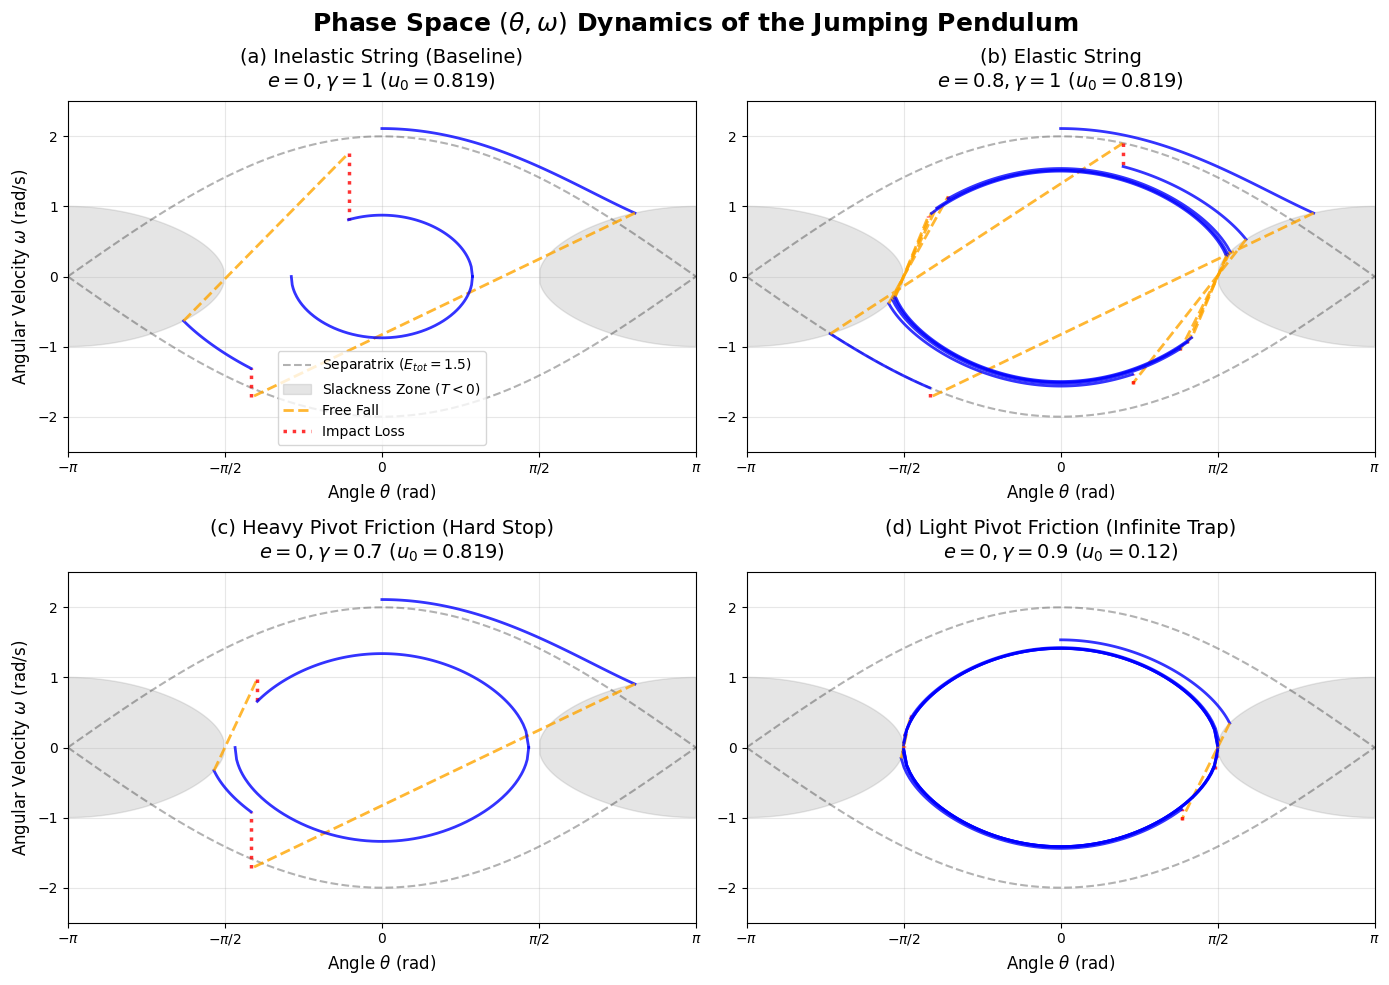

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def normalize(th):
    """Normalize angles to the [-pi, pi] domain."""
    return (th + np.pi) % (2 * np.pi) - np.pi

def calculate_impact(u, e, gamma):
    """
    Calculates the new energy state after the landing shock.
    Uses the exact discrete mapping derived in the mathematical model.
    """
    loss_n = (64/3) * (u**3) * (1 - u**2)**3
    loss_t = 3*u - (8/3)*(u**3) - loss_n

    u_next = u - (1 - e**2) * loss_n - (1 - gamma**2) * loss_t
    return u_next

def get_phase_trajectory(u0, e=0.0, gamma=1.0, max_jumps=10):
    """
    Generates the phase space coordinates (theta, omega) for the pendulum.
    Returns a list of plotting segments to handle the discontinuous jumps.
    """
    segments = []

    current_u = u0
    # Total mechanical energy mapping: E = 1.5 * u
    current_E = 1.5 * current_u

    om_sign = 1  # Start by swinging right (positive angular velocity)
    start_th = 0.0

    for n in range(max_jumps):
        if current_u <= 0:
            # PURE OSCILLATION PHASE
            # The energy is too low to reach the slackness zone.
            current_E = max(current_E, -1.0)
            th_max = om_sign * np.arccos(-current_E)

            # Swing to the turning point
            th_vals = np.linspace(start_th, th_max, 100)
            om_vals = om_sign * np.sqrt(np.maximum(0, 2*(current_E + np.cos(th_vals))))
            segments.append({'th': th_vals, 'om': om_vals, 'style': '-', 'color': 'blue'})

            # Swing back one full arc
            th_vals_back = np.linspace(th_max, -th_max, 200)
            om_vals_back = -om_sign * np.sqrt(np.maximum(0, 2*(current_E + np.cos(th_vals_back))))
            segments.append({'th': th_vals_back, 'om': om_vals_back, 'style': '-', 'color': 'blue'})
            break

        # JUMPING PHASE
        # 1. Taut swing up to the take-off point
        th_takeoff = om_sign * np.arccos(-current_u)
        th_vals = np.linspace(start_th, th_takeoff, 100)
        om_vals = om_sign * np.sqrt(np.maximum(0, 2*(current_E + np.cos(th_vals))))
        segments.append({'th': th_vals, 'om': om_vals, 'style': '-', 'color': 'blue'})

        # 2. Parabolic Free-Fall
        th_land = normalize(-3 * th_takeoff)
        om_land_minus = -om_sign * np.sqrt(np.maximum(0, 2*(current_E + np.cos(th_land))))

        segments.append({'th': [th_takeoff, th_land], 'om': [om_vals[-1], om_land_minus],
                         'style': '--', 'color': 'orange', 'label': 'Free Fall'})

        # 3. The Landing Shock
        next_u = calculate_impact(current_u, e, gamma)
        next_E = 1.5 * next_u

        # Failsafe clip
        if next_E < -np.cos(th_land):
            next_E = -np.cos(th_land)

        om_land_plus = -om_sign * np.sqrt(np.maximum(0, 2*(next_E + np.cos(th_land))))

        segments.append({'th': [th_land, th_land], 'om': [om_land_minus, om_land_plus],
                         'style': ':', 'color': 'red', 'linewidth': 2.5, 'label': 'Impact Loss'})

        current_u = next_u
        current_E = next_E
        start_th = th_land
        om_sign = -om_sign

    return segments

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()
plt.suptitle("Phase Space $(\\theta, \\omega)$ Dynamics of the Jumping Pendulum", fontsize=18, fontweight='bold')

# The models to simulate
# We use a smaller initial energy for Plot (d) to ensure it starts INSIDE the trap!
models = [
    {"title": "(a) Inelastic String (Baseline)\n$e=0, \gamma=1$ ($u_0 = 0.819$)", "e": 0.0, "gamma": 1.0, "u0": 0.819},
    {"title": "(b) Elastic String\n$e=0.8, \gamma=1$ ($u_0 = 0.819$)", "e": 0.8, "gamma": 1.0, "u0": 0.819},
    {"title": "(c) Heavy Pivot Friction (Hard Stop)\n$e=0, \gamma=0.7$ ($u_0 = 0.819$)", "e": 0.0, "gamma": 0.7, "u0": 0.819},
    {"title": "(d) Light Pivot Friction (Infinite Trap)\n$e=0, \gamma=0.9$ ($u_0 = 0.12$)", "e": 0.0, "gamma": 0.9, "u0": 0.12}
]

# Background arrays
th_bg = np.linspace(-np.pi, np.pi, 500)
separatrix_om_plus = np.sqrt(2 * (1 + np.cos(th_bg)))
separatrix_om_minus = -np.sqrt(2 * (1 + np.cos(th_bg)))

for ax, model in zip(axes, models):
    # 1. Draw the Background Aesthetics
    ax.plot(th_bg, separatrix_om_plus, 'k--', alpha=0.3, label='Separatrix ($E_{tot} = 1.5$)')
    ax.plot(th_bg, separatrix_om_minus, 'k--', alpha=0.3)

    y_slack = np.zeros_like(th_bg)
    slack_mask = (np.abs(th_bg) > np.pi/2)
    y_slack[slack_mask] = np.sqrt(-np.cos(th_bg[slack_mask]))

    ax.fill_between(th_bg, -y_slack, y_slack, where=slack_mask,
                    color='gray', alpha=0.2, label='Slackness Zone ($T < 0$)')

    # 2. Generate and Plot the Trajectory
    segments = get_phase_trajectory(model['u0'], e=model['e'], gamma=model['gamma'])

    added_labels = set()
    for seg in segments:
        label = seg.get('label', None)
        if label and label in added_labels:
            label = None
        elif label:
            added_labels.add(label)

        ax.plot(seg['th'], seg['om'], linestyle=seg['style'], color=seg['color'],
                linewidth=seg.get('linewidth', 2), alpha=0.8, label=label)

    # 3. Formatting the Axes
    ax.set_title(model['title'], fontsize=14, pad=10)
    ax.set_xlim(-np.pi, np.pi)
    ax.set_ylim(-2.5, 2.5)
    ax.set_xlabel('Angle $\\theta$ (rad)', fontsize=12)
    ax.set_xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
    ax.set_xticklabels(['$-\\pi$', '$-\\pi/2$', '0', '$\\pi/2$', '$\\pi$'])
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel('Angular Velocity $\\omega$ (rad/s)', fontsize=12)
axes[2].set_ylabel('Angular Velocity $\\omega$ (rad/s)', fontsize=12)
axes[0].legend(loc='lower center', fontsize=10)

plt.tight_layout()
plt.show()